In [1]:
# Imports generales
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Para que Python encuentre el paquete src/
sys.path.append(os.path.abspath('..'))

# Imports del proyecto modular
from src.parcial_ml import (
    riesgo_empirico,
    cargar_datos,
    entrenar_modelo_polinomico,
    experimento_para_un_dataset,
    analizar_sensibilidad,
    riesgo_validacion_promedio,
)

# Rutas
carpeta_datos = '../data'
carpeta_resultados = '../resultados'
os.makedirs(carpeta_resultados, exist_ok=True)

print("✅ Imports listos")

✅ Imports listos


In [2]:
# Le decimos a Python que busque en la carpeta padre (donde está 'src')
sys.path.append(os.path.abspath('..'))

# Importamos nuestras funciones del proyecto modular
from src.parcial_ml import (
    riesgo_empirico,
    cargar_datos,
    entrenar_modelo_polinomico,
    experimento_para_un_dataset,
)

# Definimos las rutas
carpeta_datos = '../data'
carpeta_resultados = '../resultados'
os.makedirs(carpeta_resultados, exist_ok=True)

### EJERCICIO 1

a) Entrenar 15 modelos (grados 1 al 15) usando train_A, calcular el riesgo de cada uno sobre train_A y sobre validation, y mostrar la tabla.



In [3]:
# Ejercicio 1(a): Riesgos para train_A con grados 1 al 15
grados = list(range(1, 16))

# Ejecutamos el experimento
resultados = experimento_para_un_dataset(
    carpeta_datos='../data',
    archivo_entrenamiento='train_A.csv',
    archivo_validacion='validation.csv',
    grados=grados,
    carpeta_resultados='../resultados'
)

# Mostramos la tabla con las columnas que pide el examen
resultados[['Degree', 'Train_Risk', 'Val_Risk']]


,Degree,Train_Risk,Val_Risk
0,1,0.406777,0.510432
1,2,0.327561,0.441047
2,3,0.120407,0.200026
3,4,0.118253,0.201967
4,5,0.083426,0.161396
5,6,0.082978,0.164074
6,7,0.074472,0.184270
7,8,0.069638,0.189821
8,9,0.069184,0.188407
9,10,0.065834,0.222431


Al aumentar el grado, el riesgo de entrenamiento baja constantemente, pero el de validación alcanza su mínimo en el grado 5 (0.1614) y luego comienza a subir. Este comportamiento indica sobreajuste en grados altos. El grado 5 es el mejor balance entre ajuste y generalización.


b) Grafique, en una misma figura, el riesgo de entrenamiento y el riesgo de validación en función
del grado.


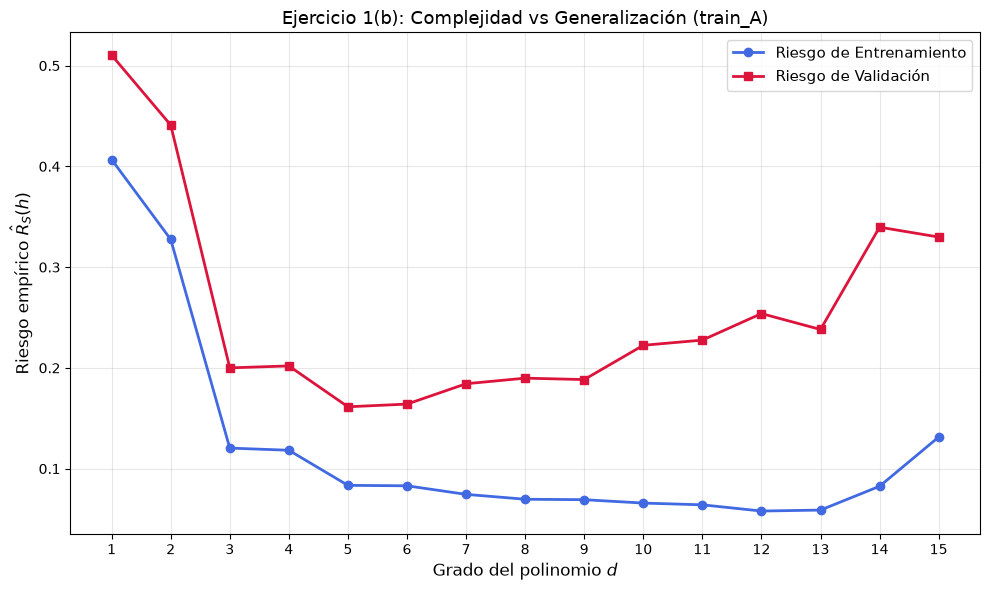

In [4]:
plt.figure(figsize=(10, 6))

# Curva del riesgo de entrenamiento (azul)
plt.plot(resultados['Degree'], resultados['Train_Risk'],
         marker='o', color='royalblue', linewidth=2,
         label='Riesgo de Entrenamiento')

# Curva del riesgo de validación (rojo)
plt.plot(resultados['Degree'], resultados['Val_Risk'],
         marker='s', color='crimson', linewidth=2,
         label='Riesgo de Validación')

plt.xlabel('Grado del polinomio $d$', fontsize=12)
plt.ylabel('Riesgo empírico $\\hat{R}_S(h)$', fontsize=12)
plt.title('Ejercicio 1(b): Complejidad vs Generalización (train_A)', fontsize=13)
plt.xticks(grados)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Guardamos la gráfica
plt.savefig(os.path.join(carpeta_resultados, 'ej1b_grafica.png'), dpi=150)
plt.show()

La gráfica muestra que el riesgo de entrenamiento (azul) disminuye constantemente al aumentar el grado, mientras que el riesgo de validación (rojo) alcanza su mínimo en el grado 5 y luego comienza a subir. La separación creciente entre ambas curvas a partir del grado 7 evidencia sobreajuste.

c) busca en la tabla cuál grado tiene el riesgo más pequeño en cada columna.

In [5]:
d_train = int(resultados.loc[resultados['Train_Risk'].idxmin(), 'Degree'])
d_val   = int(resultados.loc[resultados['Val_Risk'].idxmin(), 'Degree'])
riesgo_train_min = resultados['Train_Risk'].min()
riesgo_val_min   = resultados['Val_Risk'].min()

print(f"d_train = {d_train}   =>  riesgo mínimo de entrenamiento: {riesgo_train_min:.6f}")
print(f"d_val   = {d_val}   =>  riesgo mínimo de validación:    {riesgo_val_min:.6f}")

d_train = 12   =>  riesgo mínimo de entrenamiento: 0.057929
d_val   = 5   =>  riesgo mínimo de validación:    0.161396


El modelo que mejor se aprende los datos de memoria es el de grado 12, pero cuando le pedimos predecir datos nuevos, falla. En cambio, el grado 5 no memoriza tan bien, pero es mucho más confiable para datos nuevos. Como en la vida real queremos que el modelo funcione con datos que nunca ha visto, el grado 5 es la mejor opción.

d)Solo grados 2, 6 y 15

In [6]:
tabla_d = resultados[resultados['Degree'].isin([2, 6, 15])][['Degree', 'Train_Risk', 'Val_Risk']]
tabla_d

,Degree,Train_Risk,Val_Risk
1,2,0.327561,0.441047
5,6,0.082978,0.164074
14,15,0.131344,0.329878


El grado 2 presenta subajuste: ambos riesgos son altos (train 0.33, validación 0.44) porque el modelo es demasiado simple para capturar el patrón. El grado 6 logra el mejor balance: riesgos bajos y similares (train 0.08, validación 0.16), lo que indica buena generalización. El grado 15 sufre sobreajuste: aunque su riesgo de entrenamiento es bajo (0.13), el de validación es alto (0.33), señal de que memoriza el ruido y falla con datos nuevos.

### EJERCICIO 2

a) Para cada grado construya una gráfica que muestre simultáneamente las tres hipótesis aprendidas. Deben obtenerse tres figuras en total.

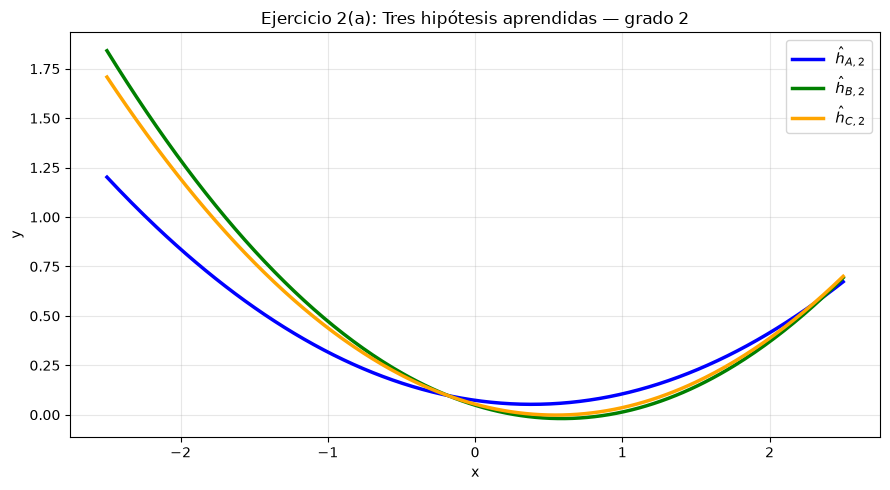

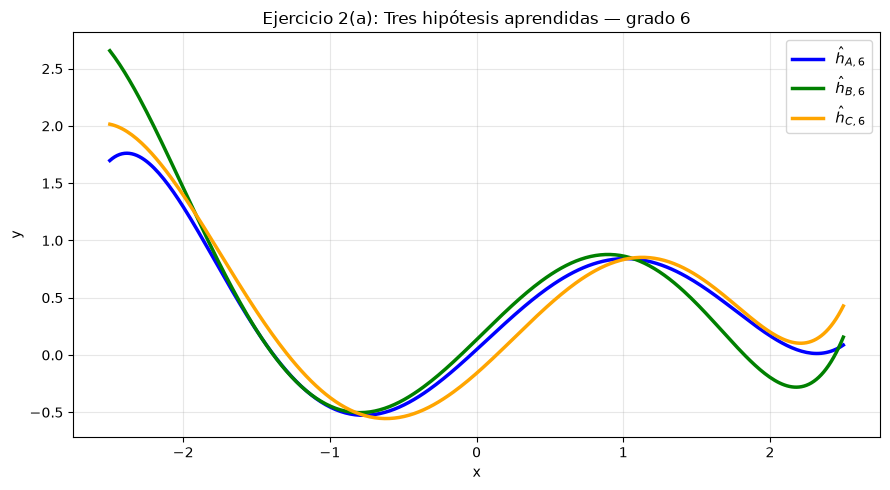

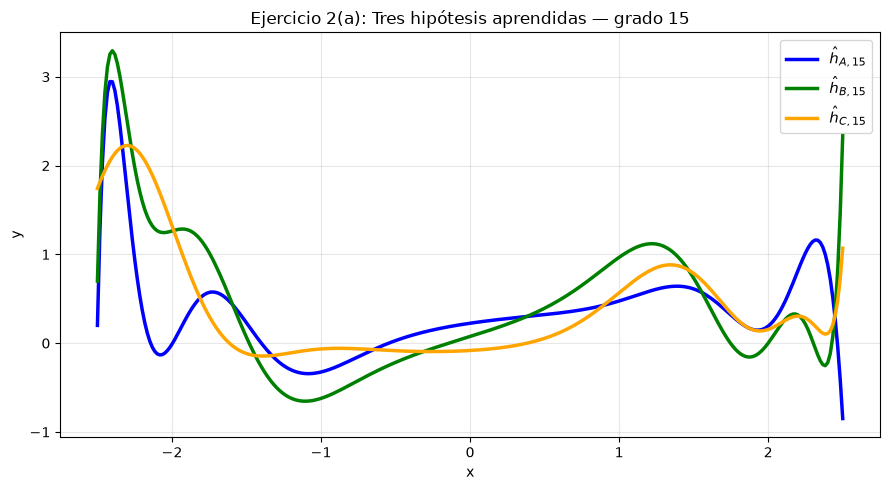

In [7]:
import sys, os
sys.path.append(os.path.abspath('..'))

from src.parcial_ml import analizar_sensibilidad

grados_ej2 = [2, 6, 15]

resultados_ej2 = analizar_sensibilidad(
    carpeta_datos='../data',
    grados=grados_ej2,
    carpeta_resultados='../resultados',
    m=300
)


En el grado 2, las 3 hipótesis son casi idénticas: el modelo no depende de la muestra porque es demasiado simple. En el grado 6, empiezan a notarse diferencias: es el punto intermedio. En el grado 15, las curvas son completamente distintas: cada modelo memoriza el ruido específico de su muestra, lo cual se reflejará en una varianza alta. Esto confirma que a mayor complejidad, mayor sensibilidad a la muestra, y que un modelo estable es preferible aunque no sea el más preciso en entrenamiento.

d) Para cada grado se calcula la varianza promedio V_d entre las 3 hipótesis, usando la malla de 300 puntos en [−2.5, 2.5]. Se reportan V₂, V₆ y V₁₅.

In [8]:
for grado in [2, 6, 15]:
    print(f"V_{grado} = {resultados_ej2[grado]['V_d']:.6f}")

V_2 = 0.009695
V_6 = 0.014151
V_15 = 0.082507


 Los números crecen con el grado: en el grado 2 las hipótesis son casi idénticas (varianza pequeña), mientras que en el grado 15 son muy diferentes (varianza grande). Esto respalda lo que ya veíamos en las gráficas: los modelos simples son estables, y los complejos cambian mucho según la muestra que se use para entrenar.

c) Se ordenan los grados según su valor de V_d y se identifica el modelo más sensible y el más estable.

In [9]:
# Ordenamos los grados por su V_d (de menor a mayor)
grados_ordenados = sorted([2, 6, 15], key=lambda g: resultados_ej2[g]['V_d'])

print("Orden de menor a mayor V_d:")
for g in grados_ordenados:
    print(f"  Grado {g}: V_{g} = {resultados_ej2[g]['V_d']:.6f}")

print()
print(f"Modelo MÁS ESTABLE:    grado {grados_ordenados[0]}  (menor V_d)")
print(f"Modelo MÁS SENSIBLE:   grado {grados_ordenados[-1]}  (mayor V_d)")

Orden de menor a mayor V_d:
  Grado 2: V_2 = 0.009695
  Grado 6: V_6 = 0.014151
  Grado 15: V_15 = 0.082507

Modelo MÁS ESTABLE:    grado 2  (menor V_d)
Modelo MÁS SENSIBLE:   grado 15  (mayor V_d)


d) Se asocia cada grado (2, 6, 15) con una categoría: alto sesgo, balance sesgo-varianza o alta varianza. Se reportan $V_d$ y el riesgo de validación promedio.

In [10]:
riesgos_val = riesgo_validacion_promedio(
    carpeta_datos='../data',
    grados=[2, 6, 15]
)

asociacion = {
    2:  'Alto sesgo',
    6:  'Balance sesgo-varianza',
    15: 'Alta varianza'
}

for grado in [2, 6, 15]:
    V_d = resultados_ej2[grado]['V_d']
    R_val = riesgos_val[grado]
    print(f"Grado {grado} → {asociacion[grado]}")
    print(f"   V_d                  = {V_d:.6f}")
    print(f"   Riesgo de validación = {R_val:.6f}")
    print()

Grado 2 → Alto sesgo
   V_d                  = 0.009695
   Riesgo de validación = 0.458920

Grado 6 → Balance sesgo-varianza
   V_d                  = 0.014151
   Riesgo de validación = 0.164837

Grado 15 → Alta varianza
   V_d                  = 0.082507
   Riesgo de validación = 0.251828



En el grado 2, el alto riesgo de validación se debe principalmente al sesgo: el modelo es muy simple y no captura el patrón. En el grado 15, el alto riesgo se debe a la varianza: el modelo es muy complejo y cambia mucho según la muestra. El grado 6 balancea ambos y por eso tiene el riesgo más bajo.

### EJERCICIO 3


a) Se calcula el riesgo promedio de validación $\overline{R}_{val}(d)$ para cada grado d ∈ {2, 6, 15}, promediando el riesgo de los 3 modelos entrenados con A, B y C.

In [11]:
import pandas as pd
tabla_ej3 = pd.DataFrame({
    'Grado': [2, 6, 15],
    'R_val(d)': [riesgos_val[g] for g in [2, 6, 15]],
    'V_d': [resultados_ej2[g]['V_d'] for g in [2, 6, 15]]
})

tabla_ej3

,Grado,R_val(d),V_d
0,2,0.458920,0.009695
1,6,0.164837,0.014151
2,15,0.251828,0.082507


El grado 6 es el mejor porque tiene el menor riesgo promedio de validación (0.1648). El grado 2 falla por alto sesgo y el grado 15 por alta varianza. El grado 6 logra el balance óptimo.

b) Se selecciona el grado 6 como el mejor modelo para entrenar futuros modelos sobre nuevas muestras.

In [12]:
mejor_grado = min([2, 6, 15], key=lambda g: riesgos_val[g])

print(f"Mejor grado: {mejor_grado}")
print(f"  R_val({mejor_grado}) = {riesgos_val[mejor_grado]:.6f}")
print(f"  V_{mejor_grado}      = {resultados_ej2[mejor_grado]['V_d']:.6f}")

Mejor grado: 6
  R_val(6) = 0.164837
  V_6      = 0.014151


Se selecciona el grado 6 como el mejor modelo para entrenar futuros modelos sobre nuevas muestras. Los dos valores que sustentan esta elección son: R val(6), que es el menor riesgo de validación entre los tres grados, y V6, que es una varianza baja que indica que el modelo es estable frente a cambios de muestra.

c) Se compara el grado seleccionado en 3(b) con el grado que produce el menor riesgo de entrenamiento en train_A.csv (calculado en el Ejercicio 1).

No coinciden. Elegimos el grado 6, pero el grado con menor error de entrenamiento es el 12. Esto pasa porque el grado 12 se aprende de memoria los datos de entrenamiento (error casi cero), pero falla cuando le damos datos nuevos. El grado 6, en cambio, no memoriza: aprende el patrón general y por eso predice mejor con datos nuevos. Por eso elegimos el 6, que es el que realmente sirve para predecir.

d) Se evalúa si la afirmación "el grado de mayor complejidad debe preferirse porque alcanza el menor riesgo de entrenamiento" es compatible con los resultados.

No estamos de acuerdo por que el error de entrenamiento no es lo que importa. Lo que importa es el error de validación (qué tan bien predice datos nuevos).